# Population parameters vs sample statistics

**A worked example using processing times, measured in minutes.**

For this notebook, define the entire population as the five jobs with processing
times **6, 8, 9, 11, 16**. Although the earlier example called these five times a
sample, here we deliberately treat them as the **complete population**.

Choose three of those jobs as an illustrative sample: **6, 9, 16**.
This subset is chosen for explanation; it is not a random draw.

We will locate both groups on a numerical x-axis, calculate their means and
standard deviations, and see why an estimate can differ from the population value.

**Run the notebook:** use a Python 3 Jupyter kernel with NumPy and Matplotlib,
then select **Run All**. Saved outputs are included so the results are also
visible without rerunning the code.

## 1. What is the difference?

| Idea | Population | Sample |
| :--- | :--- | :--- |
| Which jobs? | All five jobs in our defined group | Three selected jobs from that group |
| Observations | 6, 8, 9, 11, 16 minutes | 6, 9, 16 minutes |
| Size | $N=5$ | $n=3$ |
| Name for a numerical summary | **Parameter** | **Statistic** |
| What changes if we choose another sample? | The population parameters stay fixed | The sample statistics may change |

A **sample statistic** describes the observed sample. When we use it to infer a
population parameter, its calculated value is an **estimate**.
An **estimator** is the rule used to calculate an estimate: for example,
$\bar{x}=\sum x_i/n$.

Usually the full population is unavailable, so its parameters are unknown.
Here we know the population, which lets us compare each estimate with the truth.
These five jobs form a small teaching population; they are not necessarily all
jobs from a real delivery or processing system.

## 2. Notation and formulas

Write the population observations as $y_1,\ldots,y_N$ and the sample observations
as $x_1,\ldots,x_n$:

$$
(y_1,y_2,y_3,y_4,y_5)=(6,8,9,11,16),\qquad N=5,
$$
$$
(x_1,x_2,x_3)=(6,9,16),\qquad n=3.
$$

Sequences preserve repeated observations if they occur; a mathematical set only
records distinct values.

| Quantity | Population parameter | Sample statistic used as an estimate |
| :--- | :--- | :--- |
| Mean | $\displaystyle\mu=\frac{1}{N}\sum_{j=1}^{N}y_j$ | $\displaystyle\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i$ |
| Variance | $\displaystyle\sigma^2=\frac{\sum_{j=1}^{N}(y_j-\mu)^2}{N}$ | $\displaystyle s^2=\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}$ |
| Standard deviation | $\displaystyle\sigma=\sqrt{\sigma^2}$ | $\displaystyle s=\sqrt{s^2}$ |

The mean locates the center. Standard deviation describes spread around that
group's own mean. Mean and standard deviation are measured in **minutes**;
variance is measured in **minutes squared**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter
from IPython.display import Markdown, display

# The five observed jobs are the complete population for this example.
population = np.array([6, 8, 9, 11, 16], dtype=float)

# Select jobs by position: the first, third, and fifth jobs.
# This is an illustrative selection, not a random sample.
sample_indices = np.array([0, 2, 4])
sample = population[sample_indices]

N = population.size
n = sample.size

mu = population.mean()
population_variance = population.var(ddof=0)  # Divide by N.
sigma = population.std(ddof=0)

x_bar = sample.mean()
sample_variance = sample.var(ddof=1)          # Divide by n - 1.
s = sample.std(ddof=1)

print(f"Population: {population.astype(int).tolist()}  |  N = {N}")
print(f"Sample:     {sample.astype(int).tolist()}  |  n = {n}")

Population: [6, 8, 9, 11, 16]  |  N = 5
Sample:     [6, 9, 16]  |  n = 3


## 3. Locate the observations on the x-axis

Each dot is one job. Its horizontal position is its processing time.
Both panels use **the same x-axis scale**. Vertical position has no numerical
meaning in these two panels. A dashed line marks each group's mean.

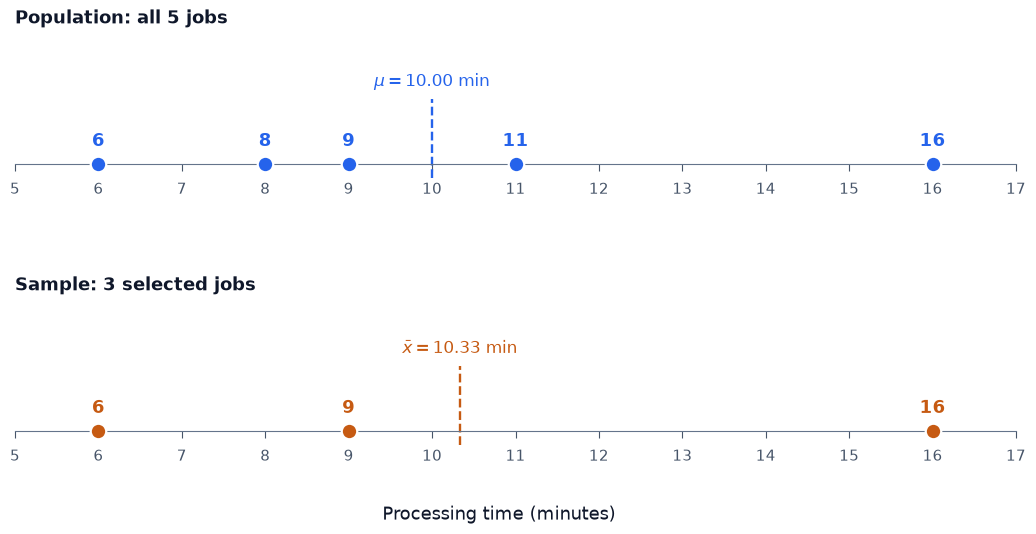

In [2]:
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titleweight": "bold",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})
population_color = "#2563eb"
sample_color = "#c65a12"
ink = "#0f172a"

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5))
panels = [
    (axes[0], population, mu, population_color,
     f"Population: all {N} jobs", rf"$\mu = {mu:.2f}$ min"),
    (axes[1], sample, x_bar, sample_color,
     f"Sample: {n} selected jobs", rf"$\bar{{x}} = {x_bar:.2f}$ min"),
]

for ax, values, center, color, title, mean_label in panels:
    ax.scatter(values, np.zeros(len(values)), s=125, color=color,
               edgecolors="white", linewidths=1.6, zorder=4)
    for value in values:
        ax.annotate(f"{value:g}", (value, 0), xytext=(0, 13),
                    textcoords="offset points", ha="center",
                    fontsize=13, fontweight="bold", color=color)
    ax.vlines(center, -0.10, 0.48, color=color,
              linestyle="--", linewidth=1.7, zorder=2)
    ax.text(center, 0.57, mean_label, ha="center", color=color, fontsize=12)
    ax.set_xlim(5, 17)
    ax.set_ylim(-0.40, 0.95)
    ax.set_xticks(np.arange(5, 18))
    ax.set_yticks([])
    for side in ("left", "right", "top"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_position(("data", 0))
    ax.spines["bottom"].set_color("#64748b")
    ax.tick_params(axis="x", colors="#475569", length=5, pad=8)
    ax.set_title(title, loc="left", color=ink, pad=8)

fig.supxlabel("Processing time (minutes)", y=0.03, color=ink)
fig.subplots_adjust(left=0.06, right=0.97, top=0.92, bottom=0.10, hspace=0.45)
plt.show()

## 4. Compare the means

The population mean uses all five observations:

$$\mu=\frac{6+8+9+11+16}{5}=\frac{50}{5}=10\text{ minutes}.$$

The sample mean uses only the three selected observations:

$$\bar{x}=\frac{6+9+16}{3}=\frac{31}{3}\approx10.333\text{ minutes}.$$

For this sample, the **estimation error** is

$$\bar{x}-\mu=\frac{31}{3}-10=\frac{1}{3}\approx+0.333\text{ minutes}.$$

The sample overestimates the population mean by about one-third of a minute.
One sample's error is not the same as an estimator's **bias**: bias concerns
the average error across repeated samples under a specified sampling method.

## 5. Compare variance and standard deviation

First subtract each group's **own mean**, then square those deviations.

In [3]:
def show_deviations(values, center, heading):
    rows = [
        "| Observation (min) | Deviation from mean (min) | Squared deviation (min²) |",
        "| ---: | ---: | ---: |",
    ]
    for value in values:
        deviation = value - center
        rows.append(f"| {value:g} | {deviation:+.4f} | {deviation**2:.4f} |")
    sum_of_squares = np.sum((values - center)**2)
    rows.append(f"| **Total squared deviations** | | **{sum_of_squares:.4f}** |")
    display(Markdown(f"**{heading}**\n\n" + "\n".join(rows)))

show_deviations(population, mu, f"Population: subtract μ = {mu:.4f}")
show_deviations(sample, x_bar, f"Sample: subtract x̄ = {x_bar:.4f}")

**Population: subtract μ = 10.0000**

| Observation (min) | Deviation from mean (min) | Squared deviation (min²) |
| ---: | ---: | ---: |
| 6 | -4.0000 | 16.0000 |
| 8 | -2.0000 | 4.0000 |
| 9 | -1.0000 | 1.0000 |
| 11 | +1.0000 | 1.0000 |
| 16 | +6.0000 | 36.0000 |
| **Total squared deviations** | | **58.0000** |

**Sample: subtract x̄ = 10.3333**

| Observation (min) | Deviation from mean (min) | Squared deviation (min²) |
| ---: | ---: | ---: |
| 6 | -4.3333 | 18.7778 |
| 9 | -1.3333 | 1.7778 |
| 16 | +5.6667 | 32.1111 |
| **Total squared deviations** | | **52.6667** |

### Population calculation

$$\sum_{j=1}^{N}(y_j-\mu)^2=16+4+1+1+36=58.$$

$$\sigma^2=\frac{58}{5}=11.6\text{ min}^2,
\qquad\sigma=\sqrt{11.6}\approx3.406\text{ min}.$$

### Sample calculation

Using the exact sample mean $31/3$ avoids rounding during the calculation:

$$\sum_{i=1}^{n}(x_i-\bar{x})^2
=\left(-\frac{13}{3}\right)^2+\left(-\frac{4}{3}\right)^2
+\left(\frac{17}{3}\right)^2=\frac{158}{3}.$$

$$s^2=\frac{158/3}{3-1}=\frac{79}{3}\approx26.333\text{ min}^2,
\qquad s=\sqrt{79/3}\approx5.132\text{ min}.$$

For this chosen sample, the estimated standard deviation is larger than the
population standard deviation. That is a result for this particular sample,
not a rule that sample standard deviations must always be larger.

In [4]:
rows = [
    "| Quantity | Population parameter | Sample statistic | Sample minus population |",
    "| :--- | ---: | ---: | ---: |",
    f"| Mean (min) | {mu:.4f} | {x_bar:.4f} | {x_bar - mu:+.4f} |",
    f"| Variance (min²) | {population_variance:.4f} | {sample_variance:.4f} | {sample_variance - population_variance:+.4f} |",
    f"| Standard deviation (min) | {sigma:.4f} | {s:.4f} | {s - sigma:+.4f} |",
]
display(Markdown("\n".join(rows)))

| Quantity | Population parameter | Sample statistic | Sample minus population |
| :--- | ---: | ---: | ---: |
| Mean (min) | 10.0000 | 10.3333 | +0.3333 |
| Variance (min²) | 11.6000 | 26.3333 | +14.7333 |
| Standard deviation (min) | 3.4059 | 5.1316 | +1.7257 |

## 6. Why does the sample formula use n − 1?

After calculating the sample mean, the deviations must sum to zero:

$$\sum_{i=1}^{n}(x_i-\bar{x})=0.$$

Once $n-1$ deviations are specified, the final deviation is determined. We say
that the deviations have **$n-1$ degrees of freedom**.

For independent observations drawn from the same distribution with finite
variance, dividing by $n-1$ makes $s^2$ an unbiased estimator of that distribution's
variance. This is a property across repeated samples; it does not guarantee
that one sample's estimate is close. Taking a square root does **not** generally
make $s$ an unbiased estimator of the standard deviation.

In NumPy, `ddof` means *delta degrees of freedom*: the divisor is the number
of observations minus `ddof`. Use `ddof=0` for the variance of the complete
population and `ddof=1` for the usual sample variance.

**Optional finite-population detail.** Our five jobs are a fixed finite population.
Under simple random sampling *without replacement*, $s^2$ is unbiased for
$S^2=\sum(y_j-\mu)^2/(N-1)$, rather than for the descriptive variance
$\sigma^2=\sum(y_j-\mu)^2/N$ used above. The adjusted estimator
$(N-1)s^2/N$ is unbiased for that descriptive variance. Our initial sample was
chosen by hand, so these repeated-random-sampling guarantees do not apply to
its selection method.

## 7. What if we selected a different sample?

There are $\binom{5}{3}=10$ distinct groups of three jobs that can be selected
without replacement. Below we enumerate **every** group and calculate its mean.
This is an exact enumeration, not a simulation.

If each group were equally likely (simple random sampling), these means would
form the exact sampling distribution of $\bar{x}$. The population mean stays
fixed at 10 minutes.

In [5]:
all_samples = np.array(list(combinations(population, n)))
all_sample_means = all_samples.mean(axis=1)
selected_row = next(
    i for i, values in enumerate(all_samples)
    if np.array_equal(values, sample)
)

rows = ["| Possible sample (minutes) | Sample mean (minutes) |",
        "| :--- | ---: |"]
for i, (values, mean) in enumerate(zip(all_samples, all_sample_means)):
    label = ", ".join(f"{v:g}" for v in values)
    if i == selected_row:
        label += " **← our sample**"
    rows.append(f"| ({label}) | {mean:.4f} |")
display(Markdown("\n".join(rows)))
print(f"Mean of all {len(all_sample_means)} sample means: {all_sample_means.mean():.4f} minutes")
print(f"Population mean: {mu:.4f} minutes")

| Possible sample (minutes) | Sample mean (minutes) |
| :--- | ---: |
| (6, 8, 9) | 7.6667 |
| (6, 8, 11) | 8.3333 |
| (6, 8, 16) | 10.0000 |
| (6, 9, 11) | 8.6667 |
| (6, 9, 16 **← our sample**) | 10.3333 |
| (6, 11, 16) | 11.0000 |
| (8, 9, 11) | 9.3333 |
| (8, 9, 16) | 11.0000 |
| (8, 11, 16) | 11.6667 |
| (9, 11, 16) | 12.0000 |

Mean of all 10 sample means: 10.0000 minutes
Population mean: 10.0000 minutes


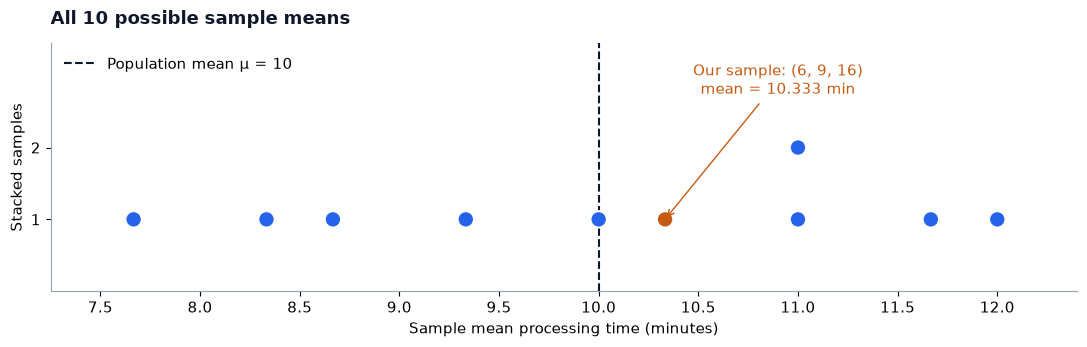

In [6]:
# Stack dots when two different samples produce the same mean.
stacks = Counter()
stack_heights = []
for mean in all_sample_means:
    key = round(float(mean), 10)
    stacks[key] += 1
    stack_heights.append(stacks[key])
stack_heights = np.array(stack_heights)
colors = [sample_color if i == selected_row else population_color
          for i in range(len(all_sample_means))]

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.scatter(all_sample_means, stack_heights, c=colors, s=140,
           edgecolors="white", linewidths=1.5, zorder=3)
ax.axvline(mu, color=ink, linestyle="--", linewidth=1.5,
           label=f"Population mean μ = {mu:g}")
sample_label = ", ".join(f"{v:g}" for v in sample)
ax.annotate(f"Our sample: ({sample_label})\nmean = {x_bar:.3f} min",
            (all_sample_means[selected_row], stack_heights[selected_row]),
            xytext=(10.9, 2.75), color=sample_color, fontsize=11,
            arrowprops={"arrowstyle": "->", "color": sample_color},
            ha="center")
ax.set_xlim(7.25, 12.4)
ax.set_ylim(0, 3.45)
ax.set_xticks(np.arange(7.5, 12.5, 0.5))
ax.set_yticks([1, 2])
ax.set_ylabel("Stacked samples")
ax.set_xlabel("Sample mean processing time (minutes)")
ax.set_title("All 10 possible sample means", loc="left", color=ink, pad=14)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#94a3b8")
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
plt.show()

Each dot in this last plot represents a **sample of three jobs**, not an
individual processing time. Two samples have a mean of 11 minutes, so those
dots are stacked. The average of all ten equally weighted sample means is
exactly 10 minutes, the population mean. This illustrates why the sample mean
is unbiased under simple random sampling, even though any particular sample
mean can be too high or too low.

## 8. What to remember

- A **parameter** describes a population; a **statistic** is calculated from a sample.
- A statistic becomes an **estimate** when it is used to infer a population parameter.
- Here, $\mu=10$ minutes and $\sigma\approx3.406$ minutes describe all five jobs.
- For the sample $(6,9,16)$, $\bar{x}\approx10.333$ minutes and $s\approx5.132$ minutes.
- A different sample can produce different estimates while the population stays fixed.
- A suitable sampling method matters. Choosing convenient observations alone does
  not guarantee that a sample represents the population.

**Try it:** replace `sample_indices = np.array([0, 2, 4])` with
`sample_indices = np.array([0, 1, 2])` and rerun the code cells. These positions
select 6, 8, and 9 minutes. Predict whether the mean and standard deviation
will increase or decrease. Code outputs update automatically; the written
worked calculations above continue to describe the original sample $(6,9,16)$.